<a href="https://colab.research.google.com/github/ahmedmohamedabdelghany8-sketch/colab-notebooks/blob/main/linear_regression_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression – California Housing

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42

## 1. Data selection and loading

In [ ]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

os.makedirs("dataset", exist_ok=True)
df.to_csv("dataset/california_housing.csv", index=False)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Preprocessing and cleaning

In [ ]:
target_column = "MedHouseVal"

print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

data = df.dropna().drop_duplicates().copy()

X = data.drop(columns=[target_column])
y = data[target_column]

print("Cleaned data shape:", data.shape)
print("Number of features:", X.shape[1])

Missing values:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Duplicate rows: 0
Cleaned data shape: (20640, 9)
Number of features: 8


## 3. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


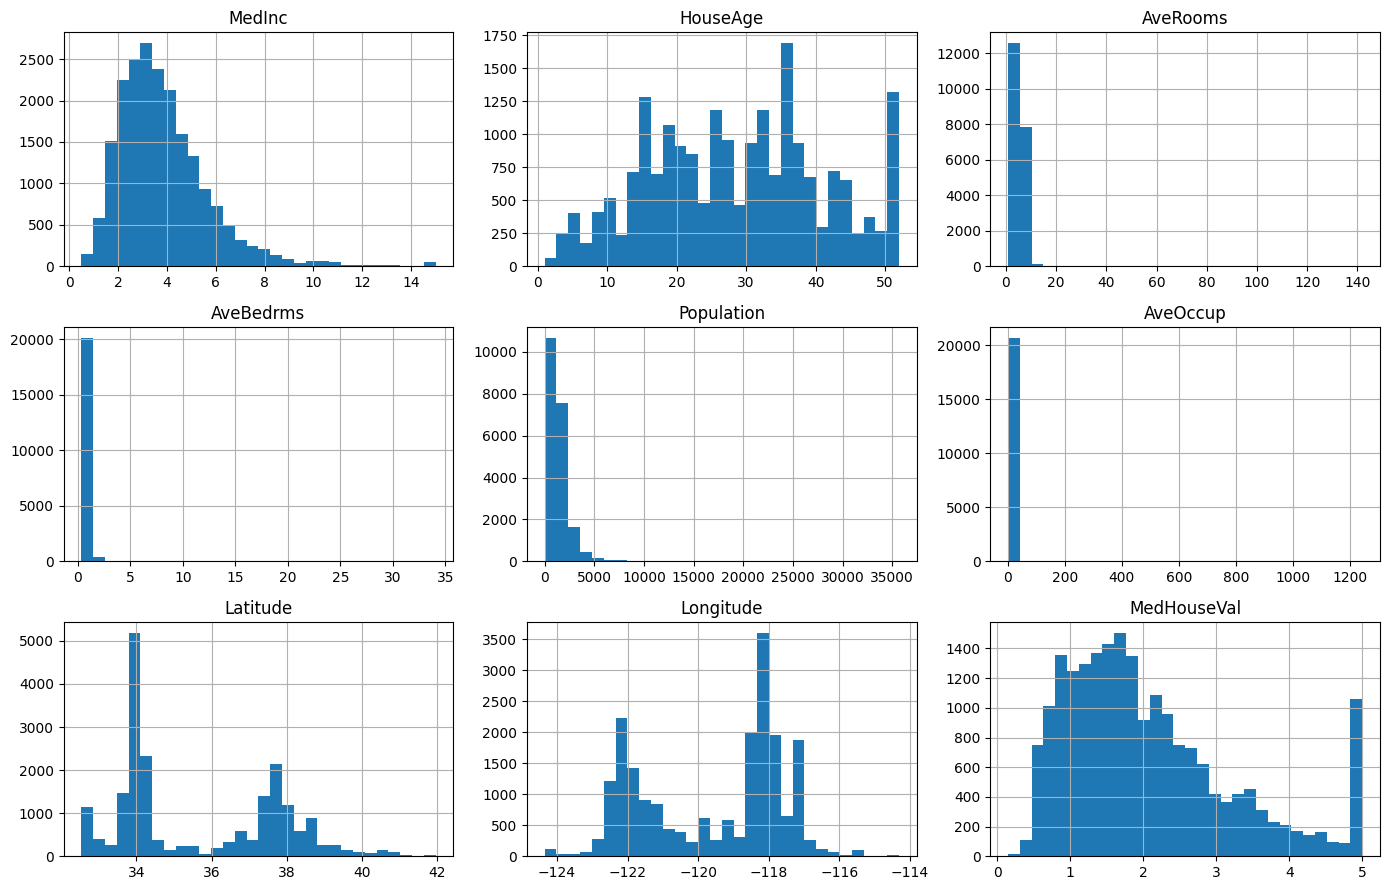

In [ ]:
display(data.describe().T)

data.hist(figsize=(14, 9), bins=30)
plt.tight_layout()
plt.show()

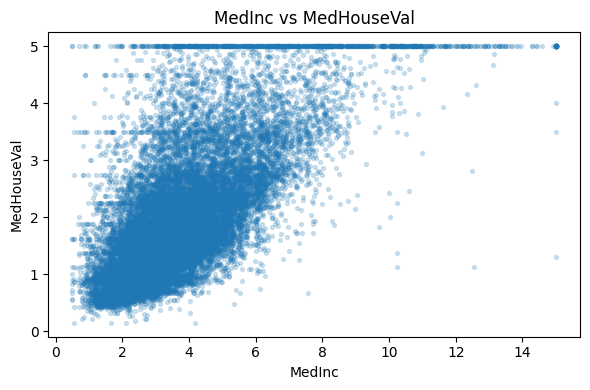

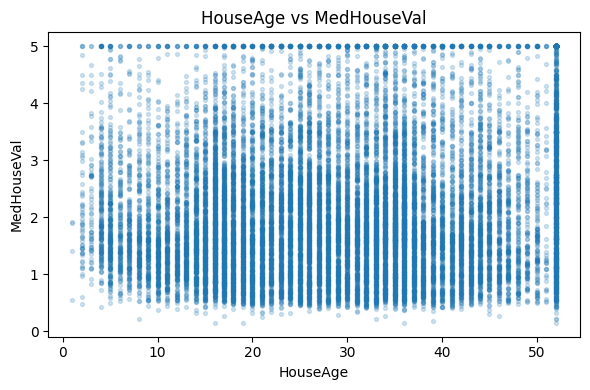

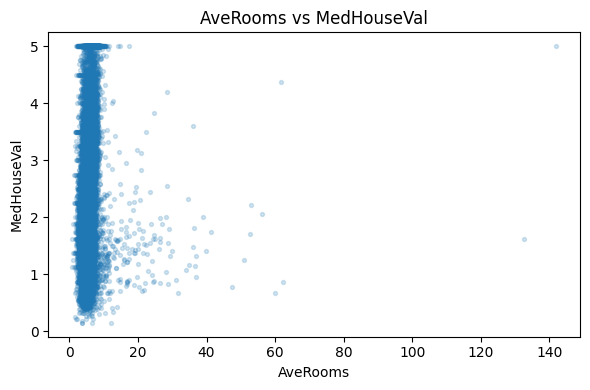

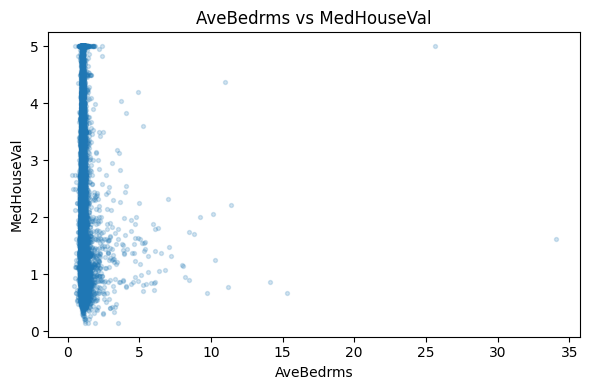

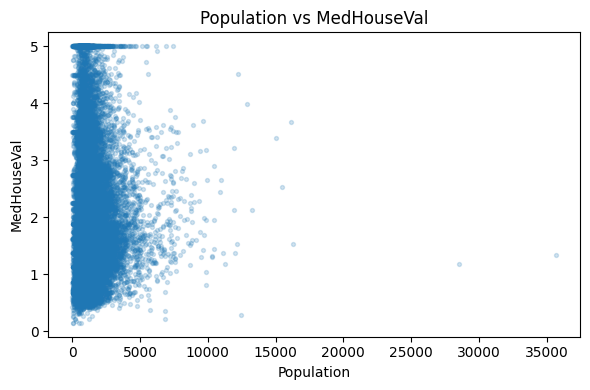

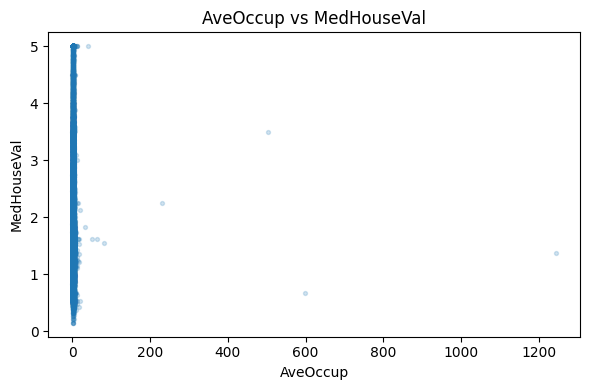

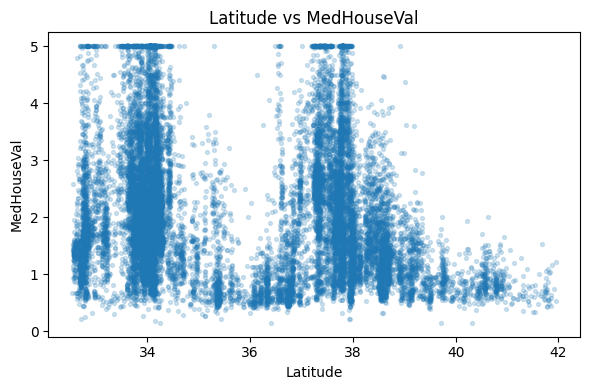

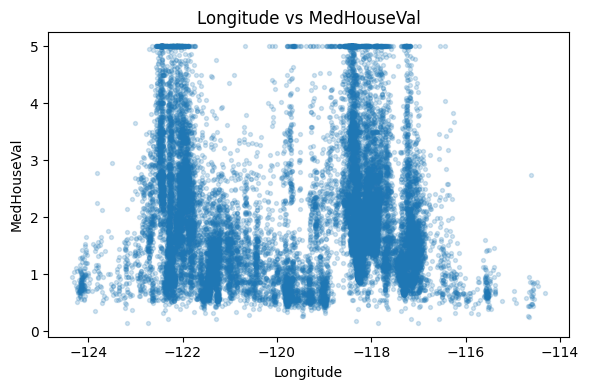

In [ ]:
for feature in X.columns:
    plt.figure(figsize=(6, 4))
    plt.scatter(X[feature], y, alpha=0.2, s=8)
    plt.xlabel(feature)
    plt.ylabel(target_column)
    plt.title(f"{feature} vs {target_column}")
    plt.tight_layout()
    plt.show()

## 4. Train/test split and model training

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model training completed.")

Training samples: 16512
Testing samples: 4128
Model training completed.


## 5. Prediction and evaluation

In [ ]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

MSE:  0.5559
RMSE: 0.7456
MAE:  0.5332


## 6. Regression line

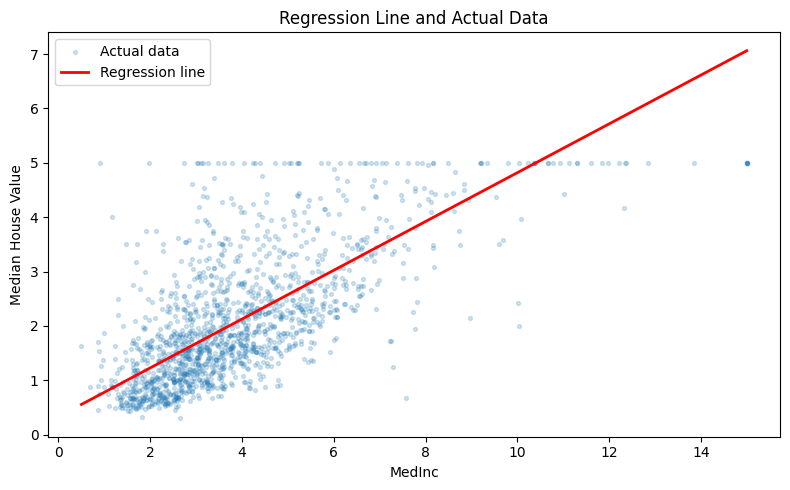

In [ ]:
# Vary MedInc and keep the other features at their mean values.
medinc_values = np.linspace(X["MedInc"].min(), X["MedInc"].max(), 200)
line_data = pd.DataFrame(
    np.tile(X.mean().values, (len(medinc_values), 1)),
    columns=X.columns
)
line_data["MedInc"] = medinc_values

line_predictions = model.predict(line_data)

sample = data.sample(n=min(1500, len(data)), random_state=RANDOM_STATE)

plt.figure(figsize=(8, 5))
plt.scatter(sample["MedInc"], sample[target_column], alpha=0.2, s=8,
            label="Actual data")
plt.plot(medinc_values, line_predictions, color="red", linewidth=2,
         label="Regression line")
plt.xlabel("MedInc")
plt.ylabel("Median House Value")
plt.title("Regression Line and Actual Data")
plt.legend()
plt.tight_layout()
plt.show()